# ¿Podemos leer una patente a partir de una foto?

**Trabajo práctico final de Procesamiento Digital de Imágenes · Primera entrega**  
Joaquin Torino, Louis Bellet e Ian Franco Tognetti · Instituto Tecnológico de Buenos Aires

Una persona mira el auto y encuentra la patente casi de inmediato. Para una computadora, la foto es una cuadrícula de píxeles. El desafío es **encontrar dónde está la placa y convertir sus trazos en texto**.

Trabajamos con patentes argentinas de formato anterior (`ABC123`) y Mercosur (`AB123CD`).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle

actual = Path.cwd()
raiz = next(
    (p for p in (actual, *actual.parents) if (p / "config/pipeline_clasico.json").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abrí el notebook desde la raíz del proyecto o desde notebooks/.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.dataset import CAJA, leer_etiquetas
from src.evaluation import iou
from src.pipeline import cargar_configuracion, preparar_motor, procesar_foto

manifiesto = json.loads((raiz / "data/examples/preentrega.json").read_text(encoding="utf-8"))
ids = ("e7eabde847dd518a92d1", "7ea9bec4563906e1ff67")
fotos = {caso["id_imagen"]: raiz / caso["foto"] for caso in manifiesto if caso["id_imagen"] in ids}
referencias = {
    fila["id_imagen"]: fila
    for fila in leer_etiquetas(raiz / "data/ground_truth.csv")
    if fila["id_imagen"] in ids and fila["particion"] == "desarrollo" and fila["estado"] == "verificada"
}

config = cargar_configuracion()
_, problema_motor = preparar_motor()
casos = {
    identificador: procesar_foto(ruta, config, problema_motor)
    for identificador, ruta in fotos.items()
    if ruta.is_file()
}
lectura, corte = (casos.get(identificador) for identificador in ids)

def mostrar_imagen(eje, imagen, titulo):
    eje.set_title(titulo, fontsize=13, color="#162e45", pad=8)
    eje.set_axis_off()
    if imagen is None:
        eje.text(.5, .5, "Sin imagen para esta etapa", ha="center", va="center", transform=eje.transAxes)
        return
    alto, ancho = imagen.shape[:2]
    eje.imshow(imagen, cmap="gray", vmin=0, vmax=255, extent=(0, ancho, alto, 0))

def mostrar_recortes(resultado, imagenes):
    fig = plt.figure(figsize=(9.6, 4.1), layout="constrained")
    rejilla = fig.add_gridspec(2, 2, height_ratios=(2, 1))
    for columna, (titulo, imagen) in enumerate(imagenes):
        mostrar_imagen(fig.add_subplot(rejilla[0, columna]), imagen, titulo)

    lienzos = [n.lienzo for _, _, n in resultado.caracteres if n is not None]
    tira = None
    if lienzos:
        separador = np.full((28, 4), 255, dtype=np.uint8)
        tira = np.hstack([pieza for lienzo in lienzos for pieza in (lienzo, separador)])[:, :-4]
    mostrar_imagen(fig.add_subplot(rejilla[1, :]), tira, "Regiones de caracteres · 28 × 28 píxeles")
    plt.show()

aviso_fotos = (
    "Para regenerar las imágenes necesitás las fotos locales de desarrollo. "
    "La preparación del conjunto está documentada en el README."
)

## Encontrar la patente

Buscamos **bordes verticales**, porque las letras y los números producen cambios bruscos de luz a sus lados. Después agrupamos los bordes vecinos para formar regiones. Entre ellas elegimos una caja por su forma, tamaño y concentración de bordes.

En la secuencia podés seguir cómo la zona de la patente pasa de ser un detalle de la foto a quedar marcada en amarillo.

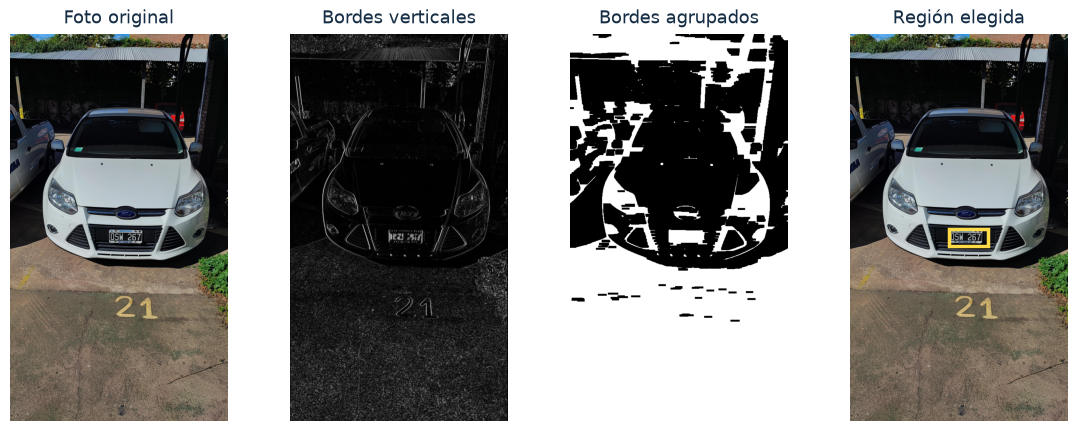

In [2]:
if lectura is None:
    print(aviso_fotos)
else:
    etapas = lectura.deteccion.imagenes if lectura.deteccion else {}
    paneles = [
        ("Foto original", lectura.foto),
        ("Bordes verticales", etapas.get("gradiente")),
        ("Bordes agrupados", etapas.get("mascara")),
        ("Región elegida", lectura.foto),
    ]
    fig, ejes = plt.subplots(1, 4, figsize=(11.2, 4.2), layout="constrained")
    for eje, (titulo, imagen) in zip(ejes, paneles):
        mostrar_imagen(eje, imagen, titulo)
    if lectura.fila["caja_detectada"]:
        x0, y0, x1, y1 = lectura.fila["caja_detectada"]
        ejes[-1].add_patch(Rectangle(
            (x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="#ffdb48", linewidth=2.5,
        ))
    else:
        ejes[-1].set_title("Sin región elegida", fontsize=13)
    plt.show()

## Pasar de imagen a texto

Una vez elegida la región, enderezamos el recorte y lo pasamos a gris. **Tesseract** hace reconocimiento óptico de caracteres (OCR). Recibe el recorte preparado y devuelve una secuencia de letras y números.

En paralelo, separamos zonas que parecen caracteres y las ponemos en cuadros del mismo tamaño. Esos cuadros serán la entrada del futuro clasificador neuronal.

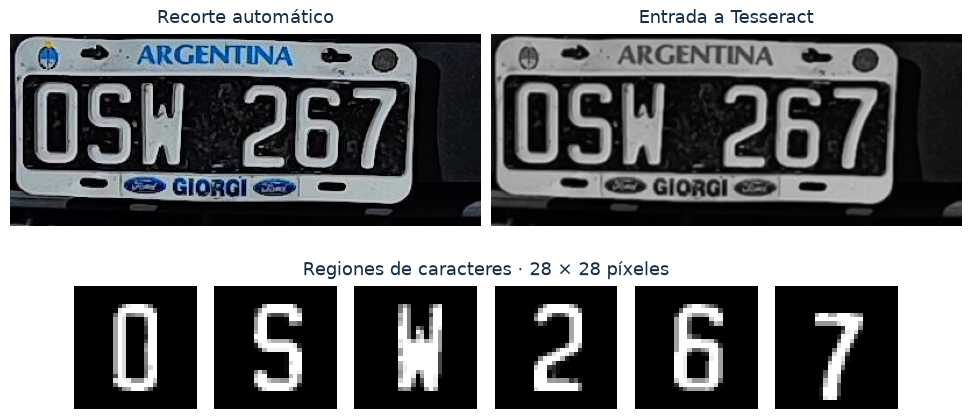

**Patente de referencia:** OSW267 · **Lectura de Tesseract:** OSW267

In [3]:
if lectura is None:
    print(aviso_fotos)
else:
    mostrar_recortes(lectura, [("Recorte automático", lectura.recorte), ("Entrada a Tesseract", lectura.entrada_ocr)])
    esperada = referencias.get(ids[0], {}).get("patente", "sin transcripción")
    obtenida = lectura.fila["texto_normalizado"] or (
        "motor no disponible" if problema_motor else "sin texto"
    )
    display(Markdown(f"**Patente de referencia:** {esperada} · **Lectura de Tesseract:** {obtenida}"))

## Cuando la caja corta un dígito

La caja automática se superpone en gran parte con la anotación, pero el recorte deja fuera casi todo el **8** final. El sistema todavía devuelve seis regiones. La última contiene apenas un fragmento.

Este caso muestra por qué conviene evaluar por separado la posición de la caja, la cantidad de regiones y la lectura.

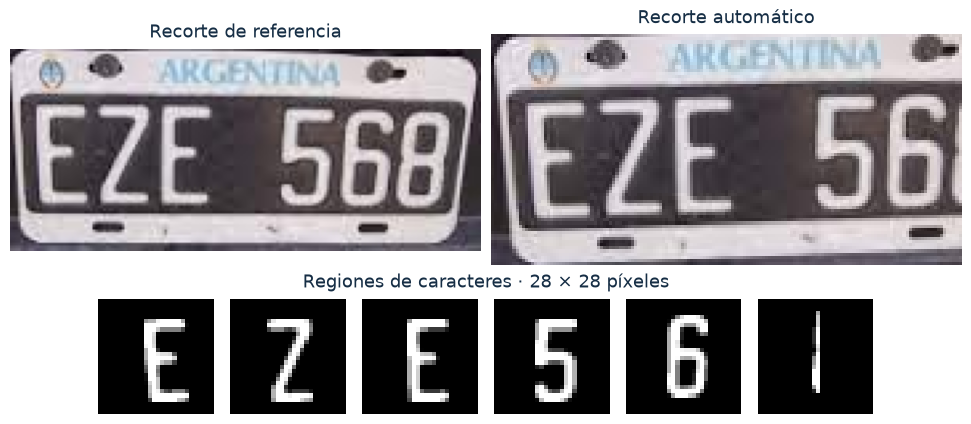

**Solapamiento de las cajas (IoU):** 0,801 · **Regiones encontradas:** 6

In [4]:
if corte is None:
    print(aviso_fotos)
else:
    referencia = referencias.get(ids[1])
    if referencia is None or corte.foto is None:
        recorte_ref = None
    else:
        caja_ref = tuple(int(referencia[coord]) for coord in CAJA)
        x0, y0, x1, y1 = caja_ref
        recorte_ref = corte.foto[y0:y1, x0:x1]
    mostrar_recortes(corte, [("Recorte de referencia", recorte_ref), ("Recorte automático", corte.recorte)])
    if recorte_ref is not None:
        solapamiento = f"{iou(caja_ref, corte.fila['caja_detectada']):.3f}".replace(".", ",")
        cantidad = corte.fila["regiones_segmentadas"]
        cantidad = cantidad if cantidad is not None else "sin segmentación"
        display(Markdown(f"**Solapamiento de las cajas (IoU):** {solapamiento} · **Regiones encontradas:** {cantidad}"))

## ¿Qué pasó en las 58 fotos de desarrollo?

Elegimos los ejemplos anteriores para explicar el proceso. Las cifras de abajo salen del conjunto usado para ajustar y comparar los métodos.

- **Localizar:** la caja alcanza un solapamiento de al menos 0,50 con la referencia. El solapamiento (IoU) divide el área en común por el área total cubierta por las dos cajas.
- **Leer:** la lectura cuenta como exacta cuando coincide toda la matrícula.
- **Separar:** se cuenta si aparecen tantas regiones como caracteres tiene la matrícula.

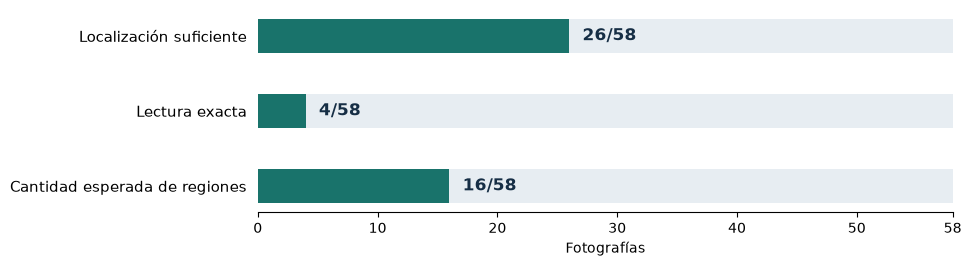

In [5]:
ruta_metricas = raiz / "results/preentrega/metricas.csv"
if ruta_metricas.is_file():
    metricas = pd.read_csv(ruta_metricas)
    detector = metricas.query("ensayo == 'localizacion' and variante == 'B3_FILTRO'").iloc[0]
    ocr = metricas.query("ensayo == 'ocr_etapa4b' and variante == 'detector_optimizado'").iloc[0]
    segmentacion = metricas.query(
        "ensayo == 'segmentacion' and variante == 'S0/fila' and tipo_recorte == 'automatico'"
    ).iloc[0]
    totales = [int(fila["imagenes"]) for fila in (detector, ocr, segmentacion)]
    valores = [
        round(detector["tasa_iou_050"] * totales[0]),
        int(ocr["aciertos"]),
        int(segmentacion["cantidad_correcta"]),
    ]
else:
    # Resultados de desarrollo de la primera entrega, documentados en PREENTREGA.md.
    totales = [58, 58, 58]
    valores = [26, 4, 16]

etiquetas = ["Localización suficiente", "Lectura exacta", "Cantidad esperada de regiones"]
fig, eje = plt.subplots(figsize=(9.6, 2.55), layout="constrained")
eje.barh(etiquetas, totales, color="#e7edf2", height=.46)
eje.barh(etiquetas, valores, color="#19736b", height=.46)
for y, (cantidad, total) in enumerate(zip(valores, totales)):
    eje.text(cantidad + 1.1, y, f"{cantidad}/{total}", va="center", fontsize=12, weight="bold", color="#162e45")
eje.invert_yaxis()
eje.set_xlim(0, max(totales))
eje.set_xticks([0, 10, 20, 30, 40, 50, max(totales)])
eje.set_xlabel("Fotografías")
eje.tick_params(axis="y", length=0, labelsize=11, pad=8)
eje.spines[["top", "right", "left"]].set_visible(False)
plt.show()

En **recortes de referencia**, la mejor configuración leyó 5 de 58 patentes completas y se obtuvo la cantidad esperada de regiones en 26 de 58. Esto ayuda a distinguir los problemas del recorte automático de las dificultades que persisten incluso cuando ya sabemos dónde está la placa.

Un segundo perfil automático obtuvo **3 lecturas exactas** y redujo la tasa de error por carácter de **79,1 % a 72,4 %**. Esa tasa cuenta cuántas inserciones, sustituciones y eliminaciones hacen falta para corregir el texto, divididas por el total de caracteres de referencia.

## Qué aprendimos y qué sigue

El sistema ya recorre el camino completo desde la foto hasta el texto. Los experimentos muestran dónde intervenir: **encontrar la placa, conservar los trazos al recortarla y mejorar la lectura**.

La segunda entrega entrenará una red neuronal para distinguir **26 letras y 10 dígitos** a partir de las regiones de 28 × 28 píxeles. Después compararemos ambas lecturas sobre las **25 fotos reservadas** para la evaluación final.

<details>
<summary>Material para preguntas técnicas y reproducción</summary>

- [Guía de defensa](../DEFENSA.md) y [resultados de la primera entrega](../PREENTREGA.md).
- [Parámetros del detector, OCR y segmentación](../config/pipeline_clasico.json) y [comandos para reproducir los ensayos](../README.md#dataset-y-reproducción-de-experimentos).
- [Origen de las fotografías y anotaciones de patente](https://universe.roboflow.com/xenon-bo5e9/patentes-argentinas-master/dataset/1).

</details>